# FINRISK · Preparación y piloto retrospectivo

**Avance de la entrega 2 · 7 de noviembre de 2026.** Este notebook audita las fuentes recuperadas, construye una etiqueta observable y compara tres modelos. Los resultados proceden de datos reales y de la ejecución registrada.

El evento del piloto es **aparecer en el siguiente inventario anual de insolvencia**, entre reportantes financieros sin presencia observada hasta el origen. No equivale a primera admisión formal en doce meses. La ausencia en el inventario no acredita solvencia. Las fechas históricas de disponibilidad y publicación siguen sin validarse: esta es una comparación retrospectiva.

Para reproducir, siga docs/entrega2/preparacion_datos.md y docs/entrega2/piloto_retrospectivo.md. Los datos individuales, las predicciones y los pesos se guardan fuera de Git. MLflow conserva los modelos y este repositorio publica resultados agregados.

In [1]:
from pathlib import Path
import json
import os
import pandas as pd

candidatas = [Path.cwd(), *Path.cwd().parents]
RAIZ = next((p for p in candidatas if (p / "requirements.txt").is_file() and (p / "src").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra el notebook desde FINRISK_COLOMBIA o su carpeta notebooks. Revise docs/entrega2/preparacion_datos.md.")
RAIZ_DATOS = Path(os.environ.get("FINRISK_DATOS_RAIZ", str(RAIZ))).expanduser().resolve()
REPORTES = RAIZ_DATOS / "reports/preparacion"
requeridos = [REPORTES / "adquisicion_financieros.json", REPORTES / "auditoria_insolvencia.json", REPORTES / "eventos_observados_insolvencia.csv", RAIZ_DATOS / "data/processed/recuperacion/base_financiera_recuperada_sin_etiquetas.csv.gz"]
faltantes = [p.relative_to(RAIZ_DATOS).as_posix() for p in requeridos if not p.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan archivos de preparación. Ejecute descarga financiera, descarga de insolvencia, auditoría y consolidación. Siga docs/entrega2/preparacion_datos.md. Archivos faltantes: " + ", ".join(faltantes))
pd.set_option("display.max_columns", 12)


## Fuentes y versión

Los estados financieros provienen de los conjuntos [situación financiera](https://www.datos.gov.co/d/pfdp-zks5) y [resultado integral](https://www.datos.gov.co/d/prwj-nzxa). Se recuperan los conceptos contables usados por el proyecto y los periodos actuales de 2019 a 2024. Las columnas originales y los identificadores de fila se conservan en archivos comprimidos. Las URLs y huellas están en el manifiesto.

Los [inventarios de insolvencia](https://www.supersociedades.gov.co/web/procedimientos-de-insolvencia/informes) son cortes administrativos. Su unión ayuda a identificar antecedentes observados. La fecha actual de admisión requiere revisión para interpretarla como primera admisión histórica.


In [2]:
adquisicion = json.loads((REPORTES / "adquisicion_financieros.json").read_text(encoding="utf-8"))
assert adquisicion["estado"] == "completo", "La descarga debe terminar antes del análisis."
fuentes = []
for nombre, fuente in adquisicion["fuentes"].items():
    assert fuente["estado"] == "completo"
    archivos = fuente["archivos"]
    fuentes.append({"fuente": nombre, "fragmentos": len(archivos), "filas": sum(a["filas"] for a in archivos.values()), "MB_comprimidos": round(sum(a["bytes_gzip"] for a in archivos.values()) / 1_000_000, 2)})
pd.DataFrame(fuentes)


,fuente,fragmentos,filas,MB_comprimidos
0,resultados,27,1196115,37.04
1,situacion,33,1507002,48.22


In [3]:
base = pd.read_csv(RAIZ_DATOS / "data/processed/recuperacion/base_financiera_recuperada_sin_etiquetas.csv.gz", dtype={"nit": str})
assert not base.duplicated(["nit", "anio"]).any()
indicadores = ["liquidez_corriente", "endeudamiento", "roa", "margen_neto"]
cobertura = base.groupby("anio").agg(empresas=("nit", "nunique"), filas=("nit", "size"), cuatro_indicadores=("indicadores_completos", "sum"), con_conflictos=("conceptos_en_conflicto", lambda s: int(s.gt(0).sum())))
cobertura


,empresas,filas,cuatro_indicadores,con_conflictos
anio,,,,
2019,25610,25610,23622,38
2020,29949,29949,26586,79
2021,29200,29200,26705,83
2022,31149,31149,28442,271
2023,31396,31396,28791,134
2024,29362,29362,27279,108


## Calidad financiera

La consolidación aplica las prioridades de reporte y concepto del código original. Cuando importes de mejor prioridad discrepan, se conserva el conflicto en la auditoría y el importe queda ausente. Esta decisión cambia la versión respecto de la primera entrega. Las fechas de corte contable se conservan. La selección por variable puede combinar reportes individuales o consolidados, radicados, taxonomías o fechas distintas. La columna requiere_revision_coherencia identifica combinaciones que necesitan revisar sus candidatos antes del modelado. La fecha de disponibilidad pública de cada reporte no está en estas fuentes y queda pendiente.

Los indicadores son razones. Endeudamiento, ROA y margen neto se multiplican por cien si se presentan como porcentajes. Liquidez se expresa en veces. Conservar valores negativos evita excluir automáticamente empresas con dificultades.


In [4]:
pd.DataFrame({"faltantes": base[indicadores].isna().sum(), "porcentaje_faltante": (base[indicadores].isna().mean() * 100).round(2)})


,faltantes,porcentaje_faltante
liquidez_corriente,3525,2.00
endeudamiento,1530,0.87
roa,1543,0.87
margen_neto,13810,7.82


In [5]:
pd.Series({"empresa_anio": len(base), "empresas_distintas": base.nit.nunique(), "patrimonio_negativo": int(base.patrimonio.lt(0).sum()), "empresa_anio_con_conflictos": int(base.conceptos_en_conflicto.gt(0).sum()), "empresa_anio_requiere_revision_coherencia": int(base.requiere_revision_coherencia.sum()), "sin_fecha_disponibilidad": int(base.fecha_disponibilidad.isna().sum())}, name="observaciones")


empresa_anio                                 176666
empresas_distintas                            37231
patrimonio_negativo                            7723
empresa_anio_con_conflictos                     713
empresa_anio_requiere_revision_coherencia      2490
sin_fecha_disponibilidad                     176666
Name: observaciones, dtype: int64

## Revisión de insolvencia

Los conteos siguientes se calculan sobre los cortes descargados. Un NIT ausente del inventario actual puede aparecer en uno antiguo. Una fecha de admisión posterior a una presencia anterior indica que debemos revisar el proceso y su historia antes de identificar la primera admisión. Estos conteos no representan positivos o negativos para entrenar.


In [6]:
insolvencia = json.loads((REPORTES / "auditoria_insolvencia.json").read_text(encoding="utf-8"))
campos_auditoria = ["nits_distintos_union_cortes", "nits_union_ausentes_ultimo_corte", "nits_con_fecha_auto_observada", "nits_con_fecha_auto_posterior_a_un_corte_de_presencia_anterior"]
pd.Series({k: insolvencia[k] for k in campos_auditoria}, name="auditoria")


nits_distintos_union_cortes                                       8075
nits_union_ausentes_ultimo_corte                                  2378
nits_con_fecha_auto_observada                                     5697
nits_con_fecha_auto_posterior_a_un_corte_de_presencia_anterior     863
Name: auditoria, dtype: int64

In [7]:
eventos = pd.read_csv(REPORTES / "eventos_observados_insolvencia.csv", dtype={"NIT": str})
assert eventos.NIT.is_unique
cruce = base.nit.isin(eventos.NIT)
pd.Series({"empresas_financieras_con_antecedente_en_algun_corte": base.loc[cruce, "nit"].nunique(), "empresa_anio_con_alguna_coincidencia": int(cruce.sum()), "empresa_anio_sin_coincidencia_observada": int((~cruce).sum())}, name="cruce_descriptivo")


empresas_financieras_con_antecedente_en_algun_corte      3189
empresa_anio_con_alguna_coincidencia                    13502
empresa_anio_sin_coincidencia_observada                163164
Name: cruce_descriptivo, dtype: int64

## Dos alcances que debemos distinguir

El objetivo inicial —primera admisión formal durante los doce meses posteriores a una evaluación— permanece pendiente de validación. Para avanzar se acordó un piloto de **presencia en inventarios**, con los cortes y exclusiones explicitados abajo. Entrenar ese piloto no resuelve las brechas del objetivo original.

In [8]:
preparacion = {
    "base_financiera_recuperada": True,
    "fuentes_insolvencia_auditadas": True,
    "fechas_disponibilidad_historica_validadas": False,
    "historial_primera_admision_validado": False,
    "ausencia_en_inventario_equivale_a_solvencia": False,
    "objetivo_original_a_doce_meses_validado": False,
}
pd.Series(preparacion, name="objetivo_original")


base_financiera_recuperada                      True
fuentes_insolvencia_auditadas                   True
fechas_disponibilidad_historica_validadas      False
historial_primera_admision_validado            False
ausencia_en_inventario_equivale_a_solvencia    False
objetivo_original_a_doce_meses_validado        False
Name: objetivo_original, dtype: bool

## Protocolo de la etiqueta del piloto

Para cada origen nominal **31 de diciembre de T**, se usan los cuatro indicadores del ejercicio **T−1** y se cruzan los NIT con diciembre de **T+1**:

- **1:** presencia observada en ese inventario.
- **0:** ausencia en ese inventario; puede haber procesos no capturados entre cortes.
- Se excluyen antecedentes observados hasta el origen, reportes con revisión de coherencia pendiente y filas sin ninguno de los cuatro indicadores.
- Se conservan faltantes parciales para imputación ajustada solo en entrenamiento e indicadores negativos.
- NIT sirve para cruce y auditoría, nunca como predictor. La fecha de admisión de 2026 no etiqueta el pasado.

Se comprueba que existan los cortes requeridos antes de asignar ceros. El protocolo conserva hashes de fuentes, reglas y conteos antes y después de excluir.

In [9]:
import sys
from IPython.display import display, Image
sys.path.insert(0, str(RAIZ / "src"))
from finrisk_piloto_datos import cargar_construir
from finrisk_piloto_modelos import entrenar_piloto, FEATURES

datos, protocolo, cohortes = cargar_construir(
    RAIZ_DATOS, salida=RAIZ_DATOS / "data/processed/piloto_retro"
)
SALIDA_MODELOS = RAIZ_DATOS / ".cache/finrisk/piloto_retrospectivo"
RESULTADOS = RAIZ / "results/piloto_retrospectivo"
RESULTADOS.mkdir(parents=True, exist_ok=True)
display(cohortes[["anio_origen", "anio_financiero", "anio_objetivo", "particion",
                  "n_modelado", "evento_1", "evento_0", "prevalencia"]])
display(pd.Series({
    "observaciones_empresa_origen": len(datos),
    "empresas_distintas": datos["nit"].nunique(),
    "version_base": protocolo["sha256_dataset"],
    "disponibilidad_historica_verificada": protocolo["disponibilidad_historica_verificada"],
}, name="etiqueta"))


,anio_origen,anio_financiero,anio_objetivo,particion,n_modelado,evento_1,evento_0,prevalencia
0,2021,2020,2022,entrenamiento,27790,125,27665,0.004498
1,2022,2021,2023,entrenamiento,27055,137,26918,0.005064
2,2023,2022,2024,validacion,28677,164,28513,0.005719
3,2024,2023,2025,prueba,28949,155,28794,0.005354


observaciones_empresa_origen                                                      112471
empresas_distintas                                                                 33608
version_base                           2b6914811285af78f01f198209eaf793f93ed1ae7696bf...
disponibilidad_historica_verificada                                                False
Name: etiqueta, dtype: object

## Particiones y restricciones temporales

| Uso | Origen | Ejercicio financiero | Inventario objetivo |
|---|---|---|---|
| Entrenamiento | 2021 y 2022 | 2020 y 2021 | diciembre de 2022 y 2023 |
| Validación | 2023 | 2022 | diciembre de 2024 |
| Prueba reservada | 2024 | 2023 | diciembre de 2025 |

La empresa puede repetirse en años distintos. El resultado corresponde a reportantes históricos y no mide exclusivamente empresas nuevas. La separación cronológica no prueba que los reportes y etiquetas estuvieran publicados en cada origen: no acredita un backtest operativo libre de información posterior.

In [10]:
display(datos.groupby("particion", sort=False).agg(
    observaciones=("evento", "size"), empresas=("nit", "nunique"),
    presencias=("evento", "sum"), prevalencia=("evento", "mean"),
))
display(pd.Series(protocolo["intersecciones_nit_particiones"],
                  name="empresas_compartidas_entre_particiones"))
display(cohortes[["anio_origen", "n_financieros",
    "excluidos_antecedente_observado", "excluidos_coherencia",
    "excluidos_sin_indicadores", "n_modelado",
    "presencias_excluidos_coherencia", "con_indicadores_imputables"]])


,observaciones,empresas,presencias,prevalencia
particion,,,,
entrenamiento,54845,29182,262,0.004777
validacion,28677,28677,164,0.005719
prueba,28949,28949,155,0.005354


entrenamiento_validacion    25807
entrenamiento_prueba        24929
validacion_prueba           26960
las_tres                    24496
Name: empresas_compartidas_entre_particiones, dtype: int64

,anio_origen,n_financieros,excluidos_antecedente_observado,excluidos_coherencia,excluidos_sin_indicadores,n_modelado,presencias_excluidos_coherencia,con_indicadores_imputables
0,2021,29949,1690,337,132,27790,1,2966
1,2022,29200,1785,359,1,27055,2,2225
2,2023,31149,1843,627,2,28677,1,2225
3,2024,31396,1952,493,2,28949,4,2244


## Tres modelos y selección previa a prueba

Se comparan referencia constante de prevalencia, regresión logística y Random Forest. Hiperparámetros y semilla están en src/finrisk_piloto_modelos.py; no se buscaron configuraciones con prueba. Imputación y escalado se ajustan solo con entrenamiento. La regresión aplica arcsinh para conservar negativos.

Se elige el modelo por mayor **AP (average precision)** en validación y el umbral por máximo **F2** en validación. F2 es un criterio técnico que pondera sensibilidad; no representa costos ni capacidad de revisión del banco. En empates se elige el modelo más simple según orden predefinido y el umbral menor con tolerancia 1e-12.

La selección y los hashes se sellan antes de evaluar una vez al ganador en prueba, sin reajustar con validación. Una ejecución íntegra se recupera de caché sin reevaluar prueba.

In [11]:
resumen = entrenar_piloto(datos, protocolo, SALIDA_MODELOS)
print("Resultado recuperado de caché:", resumen["resultado_en_cache"])
comparacion = pd.DataFrame(resumen["modelos"])
columnas = ["modelo", "ap", "sensibilidad", "precision_alertas", "f2",
            "umbral", "alertas", "fraccion_alertas"]
display(comparacion[columnas].set_index("modelo"))
print("Ganador por AP de validación:", resumen["ganador"])
print("Umbral técnico sellado:", resumen["umbral"])
print("SHA de selección:", resumen["sha256_seleccion"])


Resultado recuperado de caché: True


,ap,sensibilidad,precision_alertas,f2,umbral,alertas,fraccion_alertas
modelo,,,,,,,
referencia_prevalencia,0.005719,1.000000,0.005719,0.027955,0.004777,28677,1.000000
regresion_logistica,0.012903,0.243902,0.015163,0.060716,0.682823,2638,0.091990
bosque_aleatorio,0.017315,0.164634,0.029768,0.086372,0.744843,907,0.031628


Ganador por AP de validación: bosque_aleatorio
Umbral técnico sellado: 0.7448425229939636
SHA de selección: 540ae4175903995d90028b5a37ca9d9d3800b4f66e3cf059c9de9ae1c2f8b527


### Comparación visual en validación

AP es el promedio de precisión ponderado por incrementos de sensibilidad; no representa la precisión al umbral ni una probabilidad individual. La referencia constante tiene AP igual a la prevalencia de validación. Mejorar esa referencia no garantiza precisión operativa suficiente.

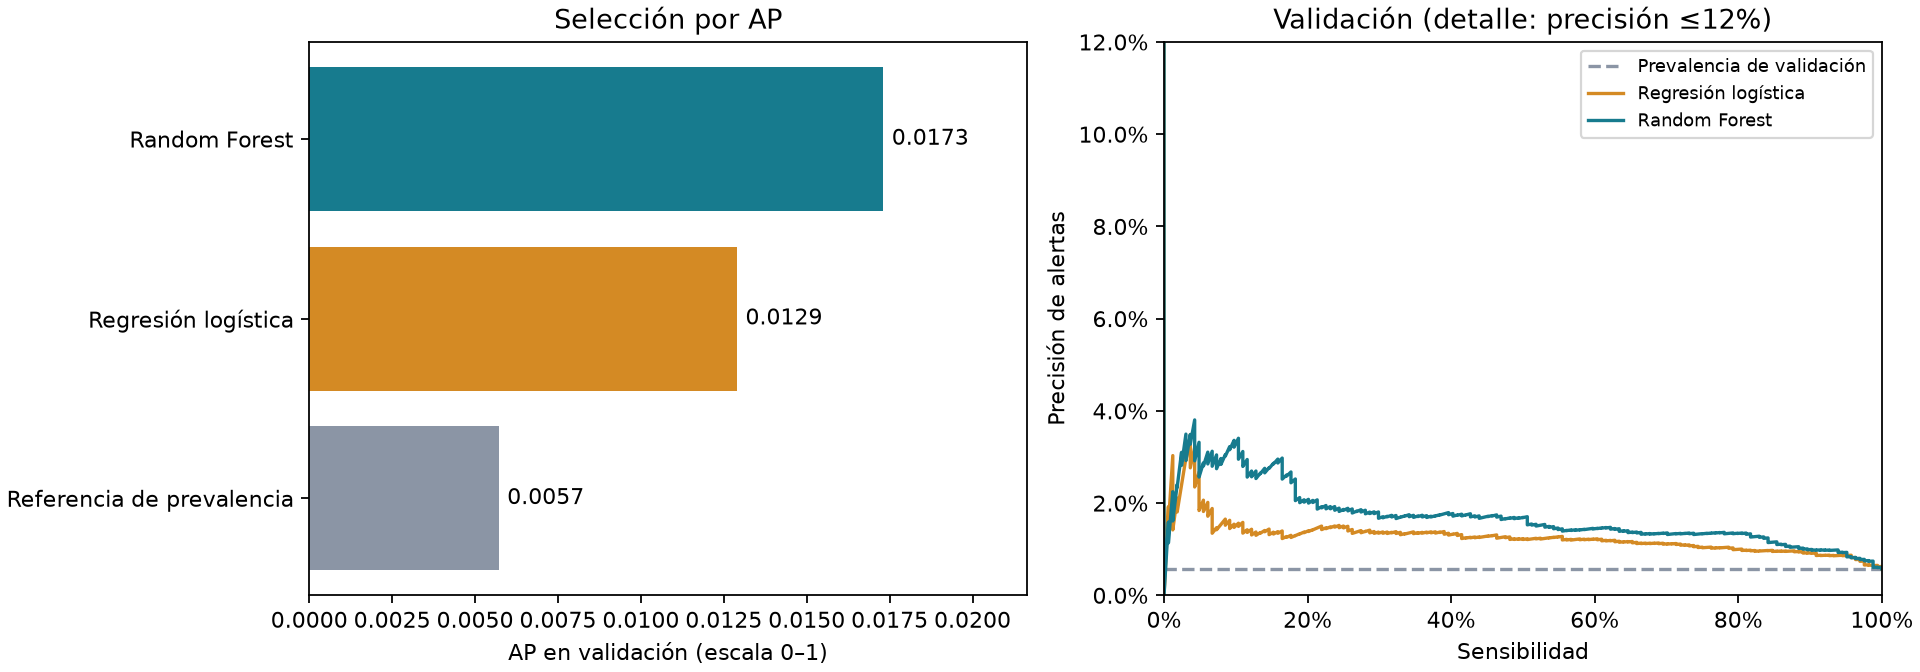

In [12]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import precision_recall_curve
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
etiquetas = {
    "referencia_prevalencia": "Referencia de prevalencia",
    "regresion_logistica": "Regresión logística",
    "bosque_aleatorio": "Random Forest",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
colores = ["#8b95a5", "#d48a24", "#177b8e"]
axes[0].barh([etiquetas[x] for x in comparacion.modelo], comparacion.ap, color=colores)
axes[0].set(xlabel="AP en validación (escala 0–1)", title="Selección por AP")
axes[0].set_xlim(0, max(comparacion.ap) * 1.25)
for i, valor in enumerate(comparacion.ap):
    axes[0].text(valor + .00025, i, f"{valor:.4f}", va="center")
for registro, color in zip(resumen["modelos"], colores):
    # round_trip conserva exactamente el puntaje de la referencia constante.
    pred = pd.read_csv(SALIDA_MODELOS / registro["archivo_predicciones"],
                       float_precision="round_trip")
    if registro["modelo"] == "referencia_prevalencia":
        axes[1].axhline(registro["prevalencia"], color=color, linestyle="--",
                        label="Prevalencia de validación", linewidth=1.5)
        continue
    precision, sensibilidad, _ = precision_recall_curve(pred["evento"], pred["puntaje"])
    axes[1].plot(sensibilidad, precision, color=color,
                 label=etiquetas[registro["modelo"]], linewidth=1.5)
axes[1].set(xlim=(0, 1), ylim=(0, .12), xlabel="Sensibilidad",
            ylabel="Precisión de alertas", title="Validación (detalle: precisión ≤12%)")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(fontsize=8)
fig.savefig(FIGURAS / "comparacion_validacion.png", dpi=160)
plt.close(fig)
display(Image(filename=str(FIGURAS / "comparacion_validacion.png")))


## Prueba: solo el modelo seleccionado

Se informa el resultado reservado del ganador, con umbral sellado. La prueba no se utilizó para escoger modelo, umbral o hiperparámetros. La referencia es presencia observada, no diagnóstico financiero completo.

modelo                            bosque_aleatorio
n                                            28949
positivos                                      155
prevalencia                               0.005354
ap                                        0.020718
umbral                                    0.744843
sensibilidad                              0.167742
precision_alertas                         0.029782
f2                                        0.087073
alertas                                        873
fraccion_alertas                          0.030156
numero_evaluaciones_prueba                       1
modelo_reajustado_antes_prueba               False
Name: prueba_reservada, dtype: object

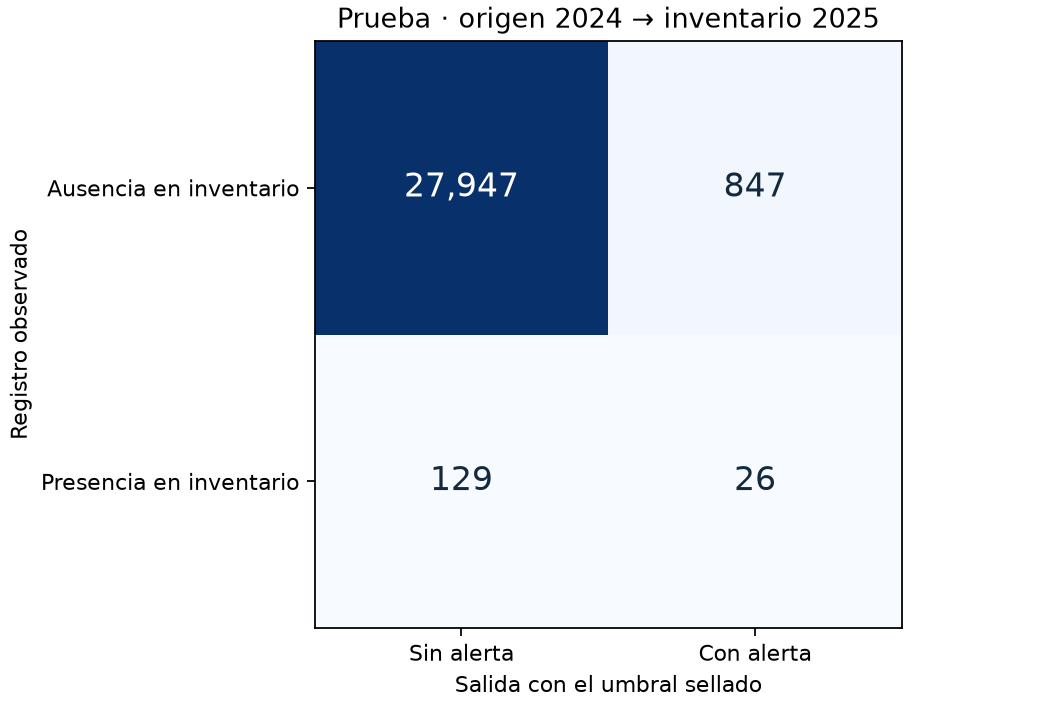

In [13]:
prueba = resumen["prueba"]
display(pd.Series({k: prueba[k] for k in [
    "modelo", "n", "positivos", "prevalencia", "ap", "umbral", "sensibilidad",
    "precision_alertas", "f2", "alertas", "fraccion_alertas",
    "numero_evaluaciones_prueba", "modelo_reajustado_antes_prueba"
]}, name="prueba_reservada"))
mc = prueba["matriz_confusion"]
matriz = [[mc["vn"], mc["fp"]], [mc["fn"], mc["vp"]]]
fig, ax = plt.subplots(figsize=(6.6, 4.4), layout="constrained")
ax.imshow(matriz, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matriz[i][j]:,}", ha="center", va="center",
                color="white" if (i, j) == (0, 0) else "#13293d", fontsize=15)
ax.set(xticks=[0, 1], xticklabels=["Sin alerta", "Con alerta"],
       yticks=[0, 1], yticklabels=["Ausencia en inventario", "Presencia en inventario"],
       xlabel="Salida con el umbral sellado", ylabel="Registro observado",
       title="Prueba · origen 2024 → inventario 2025")
fig.savefig(FIGURAS / "matriz_prueba.png", dpi=160)
plt.close(fig)
display(Image(filename=str(FIGURAS / "matriz_prueba.png")))


### Interpretación y alcance para el tablero

Random Forest detectó **26 de 155 presencias (16,77%)** y produjo **873 alertas** entre 28.949 observaciones. Solo **26 de 873 alertas (2,98%)** coincidieron con presencias en el inventario; 847 no coincidieron y 129 presencias quedaron sin alerta. AP de prueba: **0,0207**, frente a prevalencia **0,00535**. El desempeño es limitado y no respalda una decisión automática de crédito.

El tablero puede mostrar un **puntaje de presencia en inventario** y una **alerta demostrativa**. Un puntaje de 0,75 no significa “75% de probabilidad de quiebra”: no hay calibración y el balanceo de clases modifica su interpretación. Las alertas se reproducen usando predict_proba para la clase 1 y el umbral sellado; predict() emplea otro umbral.

Pendientes: disponibilidad y madurez de etiquetas, cobertura y primera admisión; desempeño por cohortes y sectores, calibración, costos y volumen de revisión. Nuevos ajustes requieren una evaluación posterior: no se debe optimizar con esta prueba ya consultada.

## Registro en MLflow

Servidor EC2: [MLflow de FINRISK](http://54.163.35.181:8050/), experimento **Proyecto-MIAD**. Tres corridas de validación conservan los pipelines; una corrida de prueba del ganador enlaza su modelo de validación. Se incluyen parámetros, métricas, protocolo, selección, versión de código y SHA de los pesos. Se comprueba la descarga del ganador. No se suben NIT ni predicciones individuales como artefactos.

El registro está desactivado al reejecutar. Para una ejecución nueva autorizada, indique un commit con exactamente el código entrenado y use el script de registro. El manifiesto documenta las corridas publicadas.

In [14]:
REGISTRAR_MLFLOW = False
COMMIT_CODIGO = ""  # Solo para una ejecución nueva con código ya versionado.
MANIFIESTO = RESULTADOS / "registro_mlflow.json"
if REGISTRAR_MLFLOW:
    from finrisk_piloto_mlflow import registrar_piloto
    registrar_piloto(SALIDA_MODELOS / "resumen_piloto.json",
                    commit_git=COMMIT_CODIGO, salida=MANIFIESTO)
if MANIFIESTO.is_file():
    registro = json.loads(MANIFIESTO.read_text(encoding="utf-8"))
    display(pd.Series({k: registro[k] for k in registro
                       if k not in ("corridas_validacion", "corrida_prueba", "verificacion_local")}, name="MLflow"))
    display(pd.DataFrame(registro["corridas_validacion"] + [registro["corrida_prueba"]]))
    display(pd.Series({"pipeline_recuperado_identico": registro["pipeline_recuperado_identico"],
                       "sha256": registro["pipeline_recuperado_sha256"]}, name="recuperacion_modelo"))
else:
    print("Manifiesto de MLflow pendiente de registrar. Esta celda no crea corridas automáticamente.")


creado_utc                                       2026-11-07T17:23:21.559117+00:00
tracking_uri                                            http://54.163.35.181:8050
experimento                                                         Proyecto-MIAD
experiment_id                                                                   2
commit_fuente                            4cd8f32162b5349919c911445a4caa0de67ebc8a
objetivo                                               presencia_inventario_anual
alcance                                                      piloto_retrospectivo
validacion_exante                                                           False
puntaje_calibrado                                                           False
version_base_etiquetada         2b6914811285af78f01f198209eaf793f93ed1ae7696bf...
pipeline_recuperado_sha256      946f7c40b079ec62a10b0b950d79d4c21f647c1e29869c...
pipeline_recuperado_identico                                                 True
filas_individual

,run_id,modelo,fase,model_uri,sha256_modelo,umbral,url,completo
0,88f119e414c2476dbecb67e8f394f36a,referencia_prevalencia,validacion,models:/m-af448fd80e434c16a142f95606791b56,2d102b90f7139c845eea5c563bf7ee030793c371896779...,0.004777,http://54.163.35.181:8050/#/experiments/2/runs...,True
1,0c70c9e248844e0b9889810ea97abbf0,regresion_logistica,validacion,models:/m-0c0f289975de4ef897e8d0c6eed7075d,b1b6ea0b0458b2f153986197462e7af514338eb5303d26...,0.682823,http://54.163.35.181:8050/#/experiments/2/runs...,True
2,93c4cd9117da48debbdabf1422454c09,bosque_aleatorio,validacion,models:/m-cb9f849d89a446ada0a5c076b10d81ab,946f7c40b079ec62a10b0b950d79d4c21f647c1e29869c...,0.744843,http://54.163.35.181:8050/#/experiments/2/runs...,True
3,b4940092f90648d8a7714fcce8b37d1a,bosque_aleatorio,prueba,models:/m-cb9f849d89a446ada0a5c076b10d81ab,946f7c40b079ec62a10b0b950d79d4c21f647c1e29869c...,0.744843,http://54.163.35.181:8050/#/experiments/2/runs...,True


pipeline_recuperado_identico                                                 True
sha256                          946f7c40b079ec62a10b0b950d79d4c21f647c1e29869c...
Name: recuperacion_modelo, dtype: object

## Soportes reproducibles

results/piloto_retrospectivo/ conserva protocolo, conteos por cohorte, métricas agregadas, selección sellada, figuras y manifiesto de MLflow. Los pesos y las predicciones individuales permanecen en la caché local; los pesos también quedan registrados en MLflow.

Los hashes permiten cotejar esta ejecución con las fuentes recuperadas. Una descarga posterior puede cambiar valores; no debe presentarse como la misma versión si sus hashes difieren. Consulte docs/entrega2/piloto_retrospectivo.md para comandos y restricciones de interpretación.